![Banner](../../../../Images/Banner/05_geostat/07_simulation.png)

# Direct Sequential Simulation (`dssim_direct`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice)

**Target:** Cadmium (`Cd`, mg/kg), simulated directly in mg/kg; zinc (`Zn`) as a secondary variable for co-simulation

**Library:** `geolattice.geostatistics`: `DirectSequentialSimulator`, `dssim_direct`, `GlobalDistribution` (module `geolattice.geostatistics.simulation.direct_sequential`, GPU engine `geolattice.geostatistics.gpu.dss_gpu`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb), [sequential Gaussian simulation](05_07_01_sgsim.ipynb), and [sequential Gaussian co-simulation](05_07_02_sgcosim.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Why Gaussian simulation misses the original-unit variogram](#why-gaussian-simulation-misses-the-original-unit-variogram)
    - 2.2 [The principle of direct sequential simulation](#the-principle-of-direct-sequential-simulation)
    - 2.3 [The global distribution](#the-global-distribution)
    - 2.4 [Soares' method](#soares-method)
    - 2.5 [The lookup-table method](#the-lookup-table-method)
    - 2.6 [Direct sequential co-simulation](#direct-sequential-co-simulation)
    - 2.7 [The GPU engine](#the-gpu-engine)
    - 2.8 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
    - 3.1 [CPU and GPU](#cpu-and-gpu)
4. [Jura Data](#jura-data)
    - 4.1 [Prediction and validation sets](#prediction-and-validation-sets)
5. [The Global Distribution with `GlobalDistribution`](#the-global-distribution-with-globaldistribution)
6. [Variograms in Original Units and in Normal Scores](#variograms-in-original-units-and-in-normal-scores)
7. [Basic Checks with `DirectSequentialSimulator`](#basic-checks-with-directsequentialsimulator)
8. [Histogram and Variogram Reproduction: Lookup vs Soares vs SGS](#histogram-and-variogram-reproduction-lookup-vs-soares-vs-sgs)
    - 8.1 [Inside the lookup table](#inside-the-lookup-table)
9. [Why Original Units Matter: Block Averages](#why-original-units-matter-block-averages)
10. [Direct Sequential Co-Simulation with Zinc](#direct-sequential-co-simulation-with-zinc)
11. [Validation at 100 Held-Out Sites](#validation-at-100-held-out-sites)
12. [Visualization of Spatial Uncertainty](#visualization-of-spatial-uncertainty)
    - 12.1 [Animated display of realizations](#animated-display-of-realizations)
    - 12.2 [Conditional quantile maps (q10, median, q90)](#conditional-quantile-maps-q10-median-q90)
    - 12.3 [Probability of exceeding the guide value](#probability-of-exceeding-the-guide-value)
13. [CPU vs GPU Timing](#cpu-vs-gpu-timing)
14. [Summary and Conclusions](#summary-and-conclusions)
    - 14.1 [Choosing the options](#choosing-the-options)
15. [References](#references)

***
## Overview

[Sequential Gaussian simulation](05_07_01_sgsim.ipynb) works on **normal scores**. It transforms the data to a standard normal distribution, models and reproduces the variogram of the scores, and back-transforms each realization. The histogram comes back right, but the variogram of the realizations *in original units* (mg/kg) is whatever the back-transform makes of the normal-score variogram. For a skewed variable, that is not the variogram you would model from the data in mg/kg.

**Direct sequential simulation** (DSS; Journel, 1994; Soares, 2001) skips the transform for kriging. It kriges the variable **in its original units**, with the original-unit variogram, and draws each value from a local distribution that has the kriging mean and the kriging variance. That is enough to reproduce the **original-unit variogram**. To reproduce the **histogram** as well, the local distribution is built from the global distribution of the data. Doing that without bias is the hard part, and GeoLattice offers the two published methods:

| `method` | Local distribution | Reproduces |
|---|---|---|
| `"lookup"` (default; Oz et al., 2003) | a back-transformed Gaussian window from a pre-computed table, chosen so its mean and variance match the kriging mean and variance | local means and variances, so the original-unit variogram; the histogram approximately |
| `"soares"` (Soares, 2001) | the kriging estimate mapped to Gaussian space, a normal draw, mapped back | values always from the global distribution, but biased upward for skewed variables, and the bias compounds |

The objects:

| Object | What it does |
|---|---|
| `GlobalDistribution` | The global cdf $F$ from (optionally declustering-weighted) data, with `cdf`, `quantile`, `to_gaussian` and `from_gaussian`, extended linearly to `zmin` / `zmax`. |
| `DirectSequentialSimulator` | The engine: `fit(grid, df, ..., secondary=None)` and `simulate(nsim, seed)`, CPU or GPU, with optional collocated co-simulation. |
| `dssim_direct` | One-call wrapper. It is named `_direct` because `dssim` is the Direct Sampling MPS simulator. |

Cadmium in the Jura topsoil is strongly skewed (skewness about 1.5), which is the case DSS is designed for. This notebook:

1. checks exact conditioning, reproducibility, and that the GPU and CPU give the same realizations;
2. compares histogram and **original-unit variogram** reproduction for the lookup method, Soares' method and SGS;
3. shows where original units matter: **block averages**, whose variance is set by the original-unit covariance;
4. co-simulates cadmium with a kriged **zinc** map, and validates every variant at 100 held-out sites.

***
## Theory

### Why Gaussian simulation misses the original-unit variogram

SGS simulates $Y(\mathbf{u})$, the normal score of $Z(\mathbf{u})$, with the normal-score covariance $C_Y(\mathbf{h})$, and returns $Z = \varphi(Y) = F^{-1}(G(Y))$. Under the multi-Gaussian model the original-unit covariance of the realizations is then fixed by $C_Y$ and $\varphi$:

$$
C_Z(\mathbf{h}) = \sum_{n \ge 1} \frac{\phi_n^2}{n!}\, \rho_Y(\mathbf{h})^n, \qquad \rho_Y = C_Y / C_Y(\mathbf{0}),
$$

where $\phi_n$ are the Hermite coefficients of $\varphi$ (the *Hermitian expansion*; Rivoirard, 1994). For a linear $\varphi$ only $n = 1$ survives and $C_Z \propto C_Y$. For a skewed variable the higher terms matter: they decay faster with distance, so the original-unit correlation $\rho_Z(\mathbf{h})$ is **lower** than $\rho_Y(\mathbf{h})$ at every lag, and the relative nugget in mg/kg is larger than in normal scores. You cannot *choose* the mg/kg variogram in SGS: it is implied.

### The principle of direct sequential simulation

Journel (1994) showed that sequential simulation reproduces a covariance $C(\mathbf{h})$ in original units **whatever the shape** of the local distributions, as long as each node is drawn from a distribution with

$$
E[Z(\mathbf{u}) \mid \cdot] = z^*_{SK}(\mathbf{u}), \qquad \operatorname{Var}[Z(\mathbf{u}) \mid \cdot] = \sigma^2_{SK}(\mathbf{u}),
$$

the simple-kriging mean and variance in original units:

$$
z^*_{SK}(\mathbf{u}) = m + \sum_\alpha \lambda_\alpha \bigl[z(\mathbf{u}_\alpha) - m\bigr], \qquad
\sum_\beta \lambda_\beta C(\mathbf{u}_\alpha - \mathbf{u}_\beta) = C(\mathbf{u}_\alpha - \mathbf{u}), \qquad
\sigma^2_{SK} = C(\mathbf{0}) - \sum_\alpha \lambda_\alpha C(\mathbf{u}_\alpha - \mathbf{u}).
$$

The argument is that simple kriging is the conditional expectation under a linear model. Drawing a residual with the right first two moments at every step reproduces the covariance between each new value and all previous ones, by induction along the path. No Gaussian assumption and no transform is needed. The sill of the variogram is the variance of $Z$ itself, in mg/kg².

The catch is the **histogram**. If the local distributions are, say, Gaussian, the realizations become Gaussian too and the skewness is lost. DSS must draw from local distributions whose shape comes from the global histogram, while still matching $z^*_{SK}$ and $\sigma^2_{SK}$.

### The global distribution

`GlobalDistribution` builds the global cdf from the data $z_{(1)} \le \dots \le z_{(n)}$ with weights $w_i$ (equal, or declustering weights, normalized to sum to 1), by the midpoint rule

$$
F(z_{(i)}) = \sum_{j \le i} w_j - \tfrac12 w_i,
$$

and extends it linearly to $F(z_{\min}) = 0$ and $F(z_{\max}) = 1$. `zmin` and `zmax` default to the data extremes and must bracket the data. The weighted mean and variance are the defaults for the simple-kriging mean $m$ and the reference variance. Its two transforms connect original units and Gaussian space:

$$
y = G^{-1}\bigl(F(z)\bigr) \quad (\texttt{to\_gaussian}), \qquad z = F^{-1}\bigl(G(y)\bigr) \quad (\texttt{from\_gaussian}).
$$

### Soares' method

Soares (2001) maps the kriging estimate into Gaussian space and draws there:

$$
y^* = G^{-1}\bigl(F(z^*_{SK})\bigr), \qquad y \sim \mathcal{N}\!\left(y^*,\; \frac{\sigma^2_{SK}}{\sigma^2_Z}\right), \qquad z = F^{-1}\bigl(G(y)\bigr).
$$

Every simulated value is a quantile of the global distribution, so the values look like the data. But the back-transformed window does not have mean $z^*_{SK}$. For a right-skewed $F$, $F^{-1}\circ G$ is convex, so by Jensen's inequality

$$
E\bigl[F^{-1}(G(y))\bigr] > F^{-1}\bigl(G(y^*)\bigr) = z^*_{SK}.
$$

Each value is biased upward. That value then conditions the next nodes, which raises their kriging estimates, and the bias **compounds** along the path. The simulated mean and variance drift above the data's. GeoLattice warns when the data skewness exceeds 1.

### The lookup-table method

Oz, Deutsch, Tran & Xie (2003) choose, at each node, the Gaussian window whose **back-transformed** mean and standard deviation match the kriging moments. The window table is computed once from $F$. For a grid of Gaussian means $y_m \in [-4, 4]$ and standard deviations $y_s \in (0, 2]$, the original-unit moments are evaluated by Gauss-Hermite quadrature with nodes $x_q$ and weights $w_q$:

$$
\mu(y_m, y_s) = \sum_q w_q\, F^{-1}\bigl(G(y_m + y_s x_q)\bigr), \qquad
s^2(y_m, y_s) = \sum_q w_q\, \bigl[F^{-1}\bigl(G(y_m + y_s x_q)\bigr)\bigr]^2 - \mu^2 .
$$

At a node with kriging moments $(z^*_{SK}, \sigma_{SK})$, the table entry nearest to them (scaled by $\sigma_Z$; a KD-tree search) gives $(y_m, y_s)$, and

$$
z = F^{-1}\bigl(G(y_m + y_s\, w)\bigr), \qquad w \sim \mathcal{N}(0, 1).
$$

The local mean and variance now equal the kriging ones up to the table resolution, so the original-unit variogram is reproduced. Because every local distribution is a piece of the global one, the histogram is reproduced **approximately**: the mixture of local windows need not equal $F$ exactly. A kriging moment pair outside the table (for example a very small mean with a large variance, which $F$ cannot produce) gets the nearest feasible window, a small departure from the exact moments.

### Direct sequential co-simulation

With an exhaustive secondary $s(\mathbf{u})$, standardized over the grid to $y_2 = (s - \bar s)/\sigma_s$, the estimate becomes **collocated simple cokriging under Markov Model 1**, exactly as in [`sgcosim`](05_07_02_sgcosim.ipynb) but in original units. With $s_0 = \sqrt{C(\mathbf{0})}$ and $\rho$ the correlation between $Z$ and the secondary,

$$
\begin{bmatrix} \mathbf{C} & \rho\, \mathbf{c}_0 / s_0 \\ \rho\, \mathbf{c}_0^\top / s_0 & 1 \end{bmatrix}
\begin{bmatrix} \boldsymbol\lambda \\ \nu \end{bmatrix}
=
\begin{bmatrix} \mathbf{c}_0 \\ \rho\, s_0 \end{bmatrix},
\qquad
z^* = m + \boldsymbol\lambda^\top(\mathbf{z} - m) + \nu\, y_2(\mathbf{u}),
\qquad
\sigma^2 = C(\mathbf{0}) - \boldsymbol\lambda^\top \mathbf{c}_0 - \nu\, \rho\, s_0 .
$$

The draw from the local distribution is unchanged. $\rho$ is the Pearson correlation of $Z$ with the secondary at the data (from `secondary_col`, or the nearest node), unless it is given. The lesson from the Gaussian co-simulation notebook applies here too: **$\rho$ must describe the secondary as it is used at the nodes**. For a kriged map, that is the correlation with a leave-one-out kriged value, not with a measurement.

### The GPU engine

Realizations are independent, so the GPU runs them in lockstep, each walking its own random path. With `method="soares"`, each realization is one CUDA thread. With `method="lookup"`, each realization is a thread **block**. One thread solves the kriging system, then all 128 threads scan slices of the window table: first in single precision to find the minimum distance, then exactly in double precision for the candidates near it. A block reduction picks the nearest window, with ties going to the smallest index, exactly as the CPU's KD-tree does. $F$ and $F^{-1}$ replicate `numpy.interp`, and the host generates every path and Gaussian deviate in the CPU engine's order, so **GPU realizations equal CPU realizations up to floating-point rounding**. Limits: `num_points` ≤ 48; spherical, exponential and Gaussian variograms. If the GPU runs out of memory, the engine warns and falls back to the CPU.

### The algorithm

For each realization:

1. Build $F$ from the data (with optional declustering `weights`, `zmin`, `zmax`); set $m$ to the weighted mean unless `mean` is given; for `"lookup"`, compute the window table.
2. Draw a random path through the grid nodes.
3. At each node:
    1. if it coincides with a datum, copy the datum;
    2. otherwise, take the `num_points` nearest informed locations within `radius` and solve simple (co)kriging in original units for $z^*$ and $\sigma^2$;
    3. draw $z$ from the local distribution (`lookup` window or Soares' Gaussian draw) and add it to the conditioning set.

No back-transform is needed at the end: the realizations are already in mg/kg.

***
## Python Setup

### CPU and GPU

`DirectSequentialSimulator(..., use_gpu=False|'auto'|True)` chooses the engine; `dssim_direct` passes `use_gpu` through.

| Value | Behaviour |
|---|---|
| `False` (default) | CPU (NumPy), one realization after another. |
| `'auto'` | GPU when CuPy can run a kernel on this card, otherwise CPU. |
| `True` | GPU. Falls back to the CPU with a warning when CuPy is missing or the GPU runs out of memory. |

The setup cell probes the GPU once. The large runs use `use_gpu=USE_GPU`, so the notebook also runs without a GPU, only more slowly.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    DirectSequentialSimulator,
    GlobalDistribution,
    OrdinaryKriging,
    Variogram,
    dssim_direct,
    sgsim_gpu,
)
from geolattice.geostatistics.gslib.nscore import nscore_forward
from geolattice.geostatistics.utils.backend import CUPY_AVAILABLE, cupy_gpu_usable

print("pygstat version:", pygstat.__version__)

USE_GPU = cupy_gpu_usable()
if USE_GPU:
    import cupy as cp
    name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    name = name.decode() if isinstance(name, bytes) else name
    print(f"CuPy            : {cp.__version__}")
    print(f"GPU (CuPy)      : {name}")
    print("Backend         : GPU (CuPy): one realization per thread (soares) or per block (lookup)")
else:
    print("CuPy            :", "installed, but cannot run a kernel here" if CUPY_AVAILABLE
          else "not installed  (pip install geolattice[geostatistics-gpu]  or  cupy-cuda13x)")
    print("Backend         : CPU (NumPy)")
print(f"use_gpu         : {USE_GPU}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44
CuPy            : 14.2.0
GPU (CuPy)      : NVIDIA RTX A5500 Laptop GPU
Backend         : GPU (CuPy): one realization per thread (soares) or per block (lookup)
use_gpu         : True


***
## Jura Data

The Jura data (Atteia et al., 1994; Goovaerts, 1997) are 359 topsoil samples from a 14.5 km² area of the Swiss Jura. `jura_grid.csv` holds 5,957 nodes on a 50 m lattice. Coordinates are in kilometres. Cadmium is strongly right-skewed, with a long upper tail up to 5 mg/kg. About two thirds of the samples exceed the Swiss guide value of 0.8 mg/kg.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df_all = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
grid = grid_df[["Xloc", "Yloc"]].to_numpy(dtype=float)
xy_all = df_all[["Xloc", "Yloc"]].to_numpy(dtype=float)

CELL = 0.05  # km
ix = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
iy = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2,
          grid[:, 1].min() - CELL / 2, grid[:, 1].max() + CELL / 2]


def to_image(values):
    img = np.full((iy.max() + 1, ix.max() + 1), np.nan)
    img[iy, ix] = values
    return img


def show_map(ax, values, title, cmap="YlOrRd", vmin=None, vmax=None, label="Cd (mg/kg)", points=None):
    im = ax.imshow(to_image(values), origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    if points is not None:
        ax.scatter(points[:, 0], points[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)
    return im


cd_all = df_all["Cd"]
print(f"Cd: n = {len(cd_all)}, mean {cd_all.mean():.3f}, sd {cd_all.std():.3f}, CV {cd_all.std() / cd_all.mean():.2f}, "
      f"skewness {cd_all.skew():.2f}, max {cd_all.max():.2f}; P(Cd > 0.8) = {(cd_all > 0.8).mean():.2f}")

Cd: n = 359, mean 1.288, sd 0.859, CV 0.67, skewness 1.48, max 5.13; P(Cd > 0.8) = 0.65


### Prediction and validation sets

As in the earlier co-simulation notebooks, 100 samples are held out at random as a **validation set**, and cadmium is used only at the other 259 sites. Zinc, used in Section 10, is known at all 359 sites.

prediction set : 259 sites, Cd mean 1.290, sd 0.848, skewness 1.49
validation set : 100 sites, Cd mean 1.283


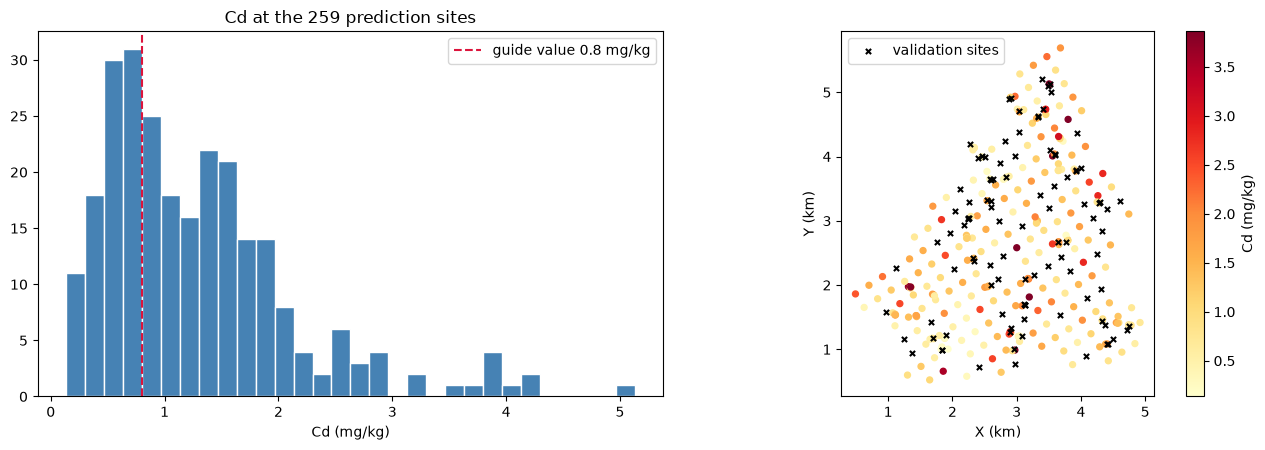

In [3]:
rng_split = np.random.default_rng(359)
test_idx = np.sort(rng_split.choice(len(df_all), size=100, replace=False))
is_test = np.zeros(len(df_all), bool)
is_test[test_idx] = True
df = df_all[~is_test].reset_index(drop=True)
test = df_all[is_test].reset_index(drop=True)
xy, xy_test = df[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
cd = df["Cd"].to_numpy(float)
truth = test["Cd"].to_numpy(float)
print(f"prediction set : {len(df)} sites, Cd mean {cd.mean():.3f}, sd {cd.std():.3f}, skewness {pd.Series(cd).skew():.2f}")
print(f"validation set : {len(test)} sites, Cd mean {truth.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(cd, bins=30, color="steelblue", edgecolor="w")
axes[0].axvline(0.8, color="crimson", ls="--", label="guide value 0.8 mg/kg")
axes[0].set_xlabel("Cd (mg/kg)")
axes[0].set_title("Cd at the 259 prediction sites")
axes[0].legend()
sc = axes[1].scatter(xy[:, 0], xy[:, 1], c=cd, s=18, cmap="YlOrRd", vmax=np.quantile(cd, 0.98))
axes[1].scatter(xy_test[:, 0], xy_test[:, 1], marker="x", c="k", s=14, label="validation sites")
axes[1].set_aspect("equal")
axes[1].set_xlabel("X (km)")
axes[1].set_ylabel("Y (km)")
axes[1].legend(loc="upper left")
plt.colorbar(sc, ax=axes[1], label="Cd (mg/kg)")
plt.tight_layout()
plt.show()

***
## The Global Distribution with `GlobalDistribution`

`GlobalDistribution` is what every DSS draw goes through. It is built here directly from the 259 cadmium values, with `zmin = 0` (cadmium cannot be negative) and `zmax = 6` mg/kg (a little above the largest sample) to bound the tails. The Jura sampling is close to regular, so equal weights are used. With clustered sampling, pass declustering `weights`.

mean 1.290  variance 0.718  (data: 1.290, 0.718)
F(0.5) = 0.129   ->  y = G^-1(F(z)) = -1.129
F(0.8) = 0.346   ->  y = G^-1(F(z)) = -0.397
F(1.5) = 0.668   ->  y = G^-1(F(z)) = +0.435
F(3.0) = 0.953   ->  y = G^-1(F(z)) = +1.670
✅ [PASS] GlobalDistribution: from_gaussian(to_gaussian(z)) == z at the data  max error 1.8e-15


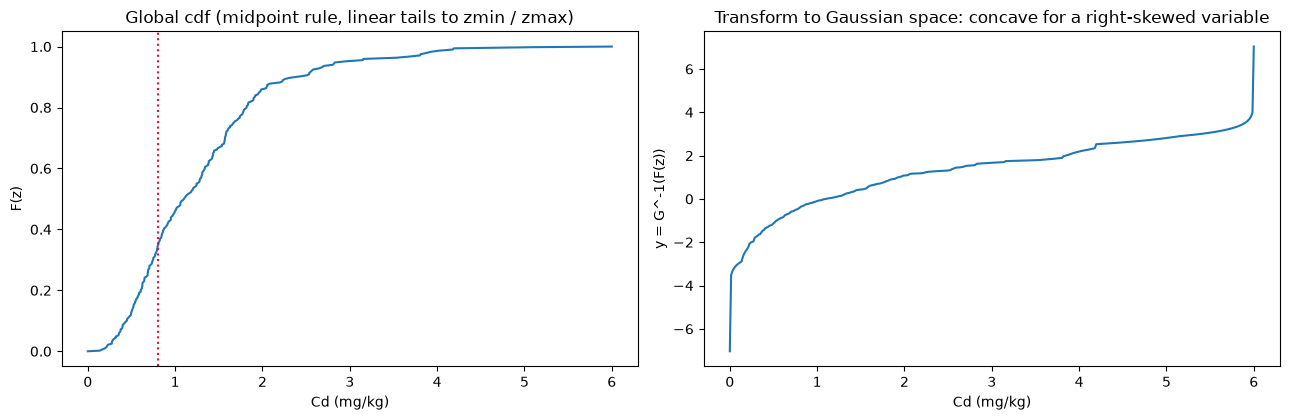

In [4]:
ZMIN, ZMAX = 0.0, 6.0
dist = GlobalDistribution(cd, zmin=ZMIN, zmax=ZMAX)
print(f"mean {dist.mean_:.3f}  variance {dist.var_:.3f}  (data: {cd.mean():.3f}, {cd.var():.3f})")
for z in [0.5, 0.8, 1.5, 3.0]:
    print(f"F({z}) = {float(dist.cdf(z)):.3f}   ->  y = G^-1(F(z)) = {float(dist.to_gaussian(z)):+.3f}")
zz = np.linspace(0, 6, 400)
yy = dist.to_gaussian(zz)
round_trip = np.abs(dist.from_gaussian(dist.to_gaussian(cd)) - cd).max()
record("GlobalDistribution: from_gaussian(to_gaussian(z)) == z at the data",
       "PASS" if round_trip < 1e-9 else "FAIL", f"max error {round_trip:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(dist.z_, dist.p_, "-", lw=1.5)
axes[0].axvline(0.8, color="crimson", ls=":")
axes[0].set_xlabel("Cd (mg/kg)")
axes[0].set_ylabel("F(z)")
axes[0].set_title("Global cdf (midpoint rule, linear tails to zmin / zmax)")
axes[1].plot(zz, yy)
axes[1].set_xlabel("Cd (mg/kg)")
axes[1].set_ylabel("y = G^-1(F(z))")
axes[1].set_title("Transform to Gaussian space: concave for a right-skewed variable")
plt.tight_layout()
plt.show()

The transform $z \mapsto y$ is concave over most of the range, so its inverse $F^{-1}\circ G$ is convex. That convexity is the source of the upward bias of Soares' method (Section 2.4).

***
## Variograms in Original Units and in Normal Scores

DSS needs the variogram of cadmium **in mg/kg**, whose sill is the cadmium variance. SGS (used for comparison) needs the variogram of the **normal scores**. Both are fitted as spherical models with the sill fixed (to the variance, and to 1) by weighted least squares.

vario_cd (mg/kg, for DSS)        : [0.0, np.float64(0.5863), np.float64(1.475), np.float64(1.475), np.float64(0.7185), 'spherical']
vario_ns (normal scores, for SGS): [0.0, np.float64(0.6237), np.float64(1.078), np.float64(1.078), 1.0, 'spherical']
relative nugget: mg/kg 0.82, normal scores 0.62


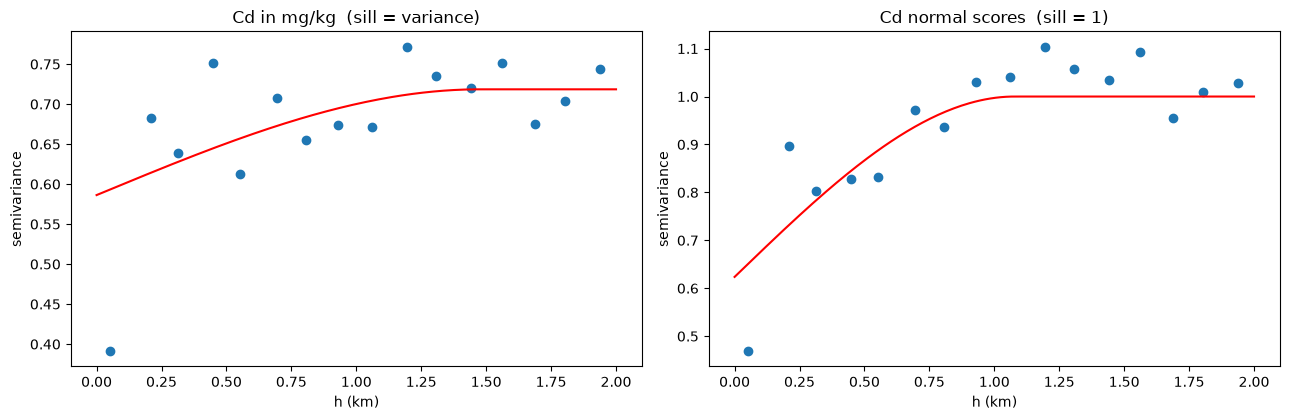

In [5]:
def experimental_variogram(xy, values, maxlag=2.0, n_lags=16):
    d = pdist(xy)
    g = 0.5 * pdist(values[:, None], "sqeuclidean")
    edges = np.linspace(0, maxlag, n_lags + 1)
    h, gam, npairs = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d > lo) & (d <= hi)
        h.append(d[m].mean()); gam.append(g[m].mean()); npairs.append(m.sum())
    return np.array(h), np.array(gam), np.array(npairs)


def spherical(h, nugget, a, sill):
    r = np.minimum(np.asarray(h, float) / a, 1.0)
    return nugget + (sill - nugget) * (1.5 * r - 0.5 * r ** 3)


def fit_spherical(xy, values, sill):
    h, g, n = experimental_variogram(xy, values)
    (nr, a), _ = curve_fit(lambda h, nr, a: spherical(h, nr * sill, a, sill), h, g, p0=[0.3, 1.0],
                           bounds=([0.0, 0.1], [0.95, 4.0]), sigma=1 / np.sqrt(n))
    return [0.0, round(nr * sill, 4), round(a, 3), round(a, 3), round(sill, 4), "spherical"], (h, g)


vario_cd, exp_cd = fit_spherical(xy, cd, cd.var())
cd_ns, _, _ = nscore_forward(cd, tails="linear")
vario_ns, exp_ns = fit_spherical(xy, cd_ns, 1.0)
print("vario_cd (mg/kg, for DSS)        :", vario_cd)
print("vario_ns (normal scores, for SGS):", vario_ns)
print(f"relative nugget: mg/kg {vario_cd[1] / vario_cd[4]:.2f}, normal scores {vario_ns[1]:.2f}")

hh = np.linspace(0, 2.0, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(*exp_cd, "o")
axes[0].plot(hh, spherical(hh, *vario_cd[1:3], vario_cd[4]), "r-")
axes[0].set_title("Cd in mg/kg  (sill = variance)")
axes[1].plot(*exp_ns, "o")
axes[1].plot(hh, spherical(hh, *vario_ns[1:3], 1.0), "r-")
axes[1].set_title("Cd normal scores  (sill = 1)")
for ax in axes:
    ax.set_xlabel("h (km)")
    ax.set_ylabel("semivariance")
plt.tight_layout()
plt.show()

The relative nugget is larger in mg/kg than in normal scores, as Section 2.1 predicts for a skewed variable: the few very high values make the raw experimental variogram erratic at short lags, and the normal-score transform tames them. Each simulator gets the variogram of the scale it kriges in.

In [6]:
NUM_POINTS = 16
RADIUS = 1.5  # km
DSS_KW = dict(num_points=NUM_POINTS, radius=RADIUS, zmin=ZMIN, zmax=ZMAX)
N_SIM = 100

***
## Basic Checks with `DirectSequentialSimulator`

On a small grid made of the 259 prediction sites plus 200 random nodes:

* the data are reproduced exactly;
* realizations vary away from the data;
* the same seed gives the same realizations;
* GPU = CPU for both methods;
* `dssim_direct` equals the class.

In [7]:
pick = np.random.default_rng(0).choice(len(grid), 200, replace=False)
small_grid = np.vstack([xy, grid[pick]])

dss = DirectSequentialSimulator(vario_cd, method="lookup", use_gpu=USE_GPU, **DSS_KW).fit(
    small_grid, df, "Xloc", "Yloc", "Cd")
sims_a, sims_b, sims_c = dss.simulate(8, seed=11), dss.simulate(8, seed=11), dss.simulate(8, seed=12)

err = np.abs(sims_a[:, :len(df)] - cd).max()
record("DSS: exact conditioning", "PASS" if err < 1e-9 else "FAIL", f"max |sim - data| = {err:.1e}")
spread = sims_a[:, len(df):].std(axis=0).mean()
record("DSS: realizations vary away from data", "PASS" if spread > 0.1 else "FAIL",
       f"mean std across realizations = {spread:.2f} mg/kg")
record("DSS: same seed -> identical", "PASS" if np.array_equal(sims_a, sims_b) else "FAIL")
record("DSS: different seed -> different", "PASS" if not np.allclose(sims_a, sims_c) else "FAIL")

for method in ["lookup", "soares"]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cpu = DirectSequentialSimulator(vario_cd, method=method, **DSS_KW).fit(small_grid, df, "Xloc", "Yloc", "Cd")
        gpu = DirectSequentialSimulator(vario_cd, method=method, use_gpu=USE_GPU, **DSS_KW).fit(
            small_grid, df, "Xloc", "Yloc", "Cd")
    diff = np.abs(cpu.simulate(8, seed=11) - gpu.simulate(8, seed=11)).max()
    record(f"DSS ({method}): GPU = CPU for the same seed", "PASS" if diff < 1e-6 else "FAIL",
           f"max diff = {diff:.1e} mg/kg" + ("" if USE_GPU else " (no GPU: both ran on CPU)"))

one_call = dssim_direct(small_grid, df, "Xloc", "Yloc", "Cd", vario_cd, nsim=8, seed=11, **DSS_KW)
record("dssim_direct == DirectSequentialSimulator(...).simulate", "PASS" if np.allclose(one_call, sims_a) else "FAIL",
       f"max diff = {np.abs(one_call - sims_a).max():.1e}")

✅ [PASS] DSS: exact conditioning  max |sim - data| = 0.0e+00
✅ [PASS] DSS: realizations vary away from data  mean std across realizations = 0.67 mg/kg
✅ [PASS] DSS: same seed -> identical  
✅ [PASS] DSS: different seed -> different  


✅ [PASS] DSS (lookup): GPU = CPU for the same seed  max diff = 2.8e-14 mg/kg


✅ [PASS] DSS (soares): GPU = CPU for the same seed  max diff = 2.8e-14 mg/kg
✅ [PASS] dssim_direct == DirectSequentialSimulator(...).simulate  max diff = 2.8e-14


Soares' method warns when the data are strongly skewed:

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    DirectSequentialSimulator(vario_cd, method="soares", **DSS_KW).fit(small_grid, df, "Xloc", "Yloc", "Cd")
for w in caught:
    print(f"{w.category.__name__}: {w.message}")
record("soares warns for skewed data", "PASS" if caught else "FAIL")
warnings.filterwarnings("ignore")

✅ [PASS] soares warns for skewed data  


***
## Histogram and Variogram Reproduction: Lookup vs Soares vs SGS

Each method draws 100 realizations on the full grid:

| Method | Variogram used | Units of kriging |
|---|---|---|
| DSS lookup | `vario_cd` | mg/kg |
| DSS Soares | `vario_cd` | mg/kg |
| SGS (`sgsim_gpu`, `itrans=True`) | `vario_ns` | normal scores, back-transformed |

They are compared on the **histogram** (mean, standard deviation and quantiles of each realization, averaged) and on the **variogram in mg/kg** of the realizations, computed on 1,500 random nodes, against the mg/kg model.

In [9]:
t0 = time.perf_counter()
real = {
    "DSS lookup": DirectSequentialSimulator(vario_cd, method="lookup", use_gpu=USE_GPU, **DSS_KW).fit(
        grid, df, "Xloc", "Yloc", "Cd").simulate(N_SIM, seed=2024),
    "DSS Soares": DirectSequentialSimulator(vario_cd, method="soares", use_gpu=USE_GPU, **DSS_KW).fit(
        grid, df, "Xloc", "Yloc", "Cd").simulate(N_SIM, seed=2024),
    "SGS": sgsim_gpu(grid, df, "Xloc", "Yloc", "Cd", vario_ns, num_points=NUM_POINTS, radius=RADIUS,
                     nsim=N_SIM, seed=2024, zmin=ZMIN, zmax=ZMAX, use_gpu=USE_GPU),
}
print(f"3 x {N_SIM} realizations x {len(grid)} nodes in {time.perf_counter() - t0:.1f} s")

rows = [{"method": "data (259)", "mean": cd.mean(), "sd": cd.std(), "q10": np.quantile(cd, .1),
         "median": np.median(cd), "q90": np.quantile(cd, .9), "P(>0.8)": (cd > 0.8).mean()}]
for name, r in real.items():
    rows.append({"method": name, "mean": r.mean(1).mean(), "sd": r.std(1).mean(),
                 "q10": np.quantile(r, .1, axis=1).mean(), "median": np.median(r, axis=1).mean(),
                 "q90": np.quantile(r, .9, axis=1).mean(), "P(>0.8)": (r > 0.8).mean()})
hist_table = pd.DataFrame(rows).set_index("method")
hist_table.round(3)

3 x 100 realizations x 5957 nodes in 8.0 s


,mean,sd,q10,median,q90,P(>0.8)
method,,,,,,
data (259),1.290,0.848,0.448,1.100,2.335,0.653
DSS lookup,1.303,0.843,0.404,1.176,2.402,0.669
DSS Soares,1.746,1.080,0.617,1.549,3.512,0.808
SGS,1.301,0.828,0.466,1.143,2.339,0.672


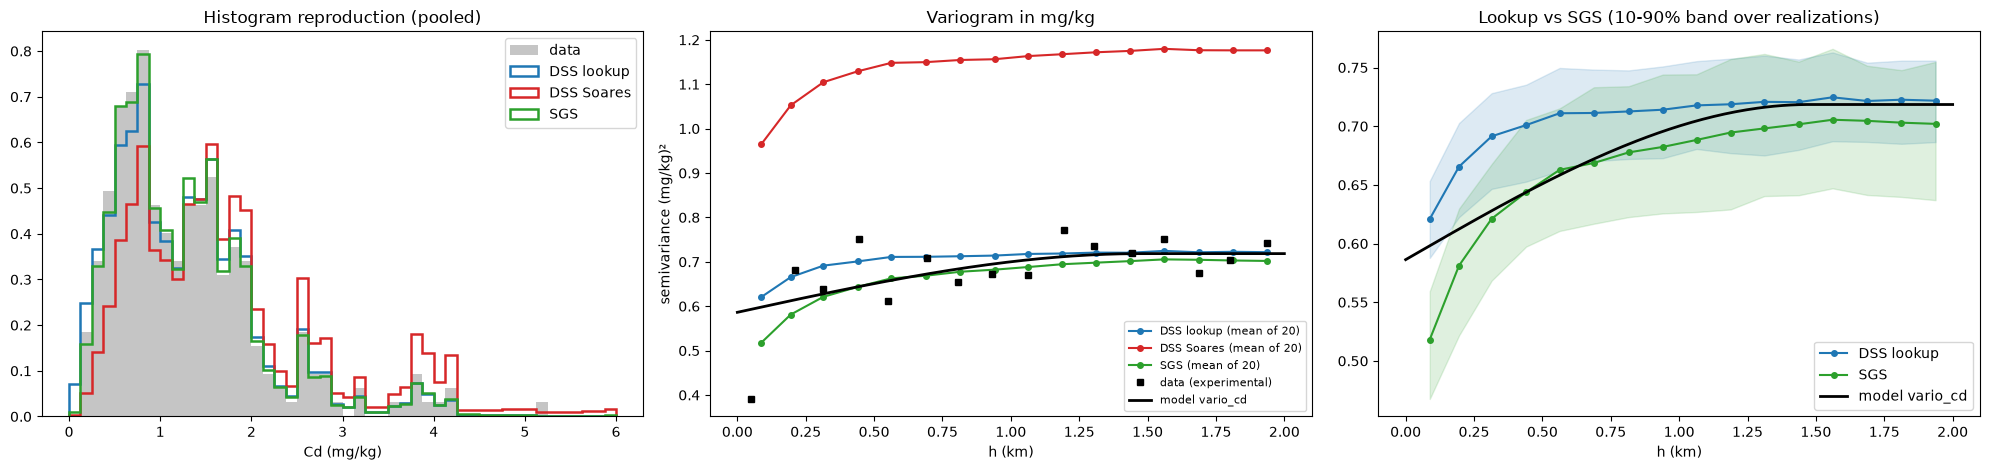

DSS lookup : mean |gamma_sim - model| over lags = 0.024 (mg/kg)²; first lag 0.621 vs model 0.598
DSS Soares : mean |gamma_sim - model| over lags = 0.458 (mg/kg)²; first lag 0.965 vs model 0.598
SGS        : mean |gamma_sim - model| over lags = 0.017 (mg/kg)²; first lag 0.518 vs model 0.598
✅ [PASS] DSS lookup reproduces the mean within 5%  1.303 vs data 1.290
✅ [PASS] DSS Soares drifts upward on skewed data (expected)  mean 1.746 vs data 1.290


In [10]:
sub = np.random.default_rng(5).choice(len(grid), 1500, replace=False)
gam = {name: np.array([experimental_variogram(grid[sub], r[i, sub])[1] for i in range(20)]) for name, r in real.items()}
h_sub = experimental_variogram(grid[sub], real["SGS"][0, sub])[0]

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
bins = np.linspace(0, 6, 49)
axes[0].hist(cd, bins=bins, density=True, alpha=0.45, color="0.5", label="data")
for (name, r), c in zip(real.items(), ["tab:blue", "tab:red", "tab:green"]):
    axes[0].hist(r.ravel(), bins=bins, density=True, histtype="step", lw=1.8, color=c, label=name)
axes[0].set_xlabel("Cd (mg/kg)")
axes[0].set_title("Histogram reproduction (pooled)")
axes[0].legend()

for (name, g), c in zip(gam.items(), ["tab:blue", "tab:red", "tab:green"]):
    axes[1].plot(h_sub, g.mean(0), "o-", ms=4, c=c, label=f"{name} (mean of 20)")
axes[1].plot(*exp_cd, "ks", ms=4, label="data (experimental)")
axes[1].plot(hh, spherical(hh, *vario_cd[1:3], vario_cd[4]), "k-", lw=2, label="model vario_cd")
axes[1].set_xlabel("h (km)")
axes[1].set_ylabel("semivariance (mg/kg)²")
axes[1].set_title("Variogram in mg/kg")
axes[1].legend(fontsize=8)

for (name, g), c in zip(gam.items(), ["tab:blue", "tab:red", "tab:green"]):
    if name != "DSS Soares":
        axes[2].plot(h_sub, g.mean(0), "o-", ms=4, c=c, label=name)
        axes[2].fill_between(h_sub, *np.percentile(g, [10, 90], axis=0), color=c, alpha=0.15)
axes[2].plot(hh, spherical(hh, *vario_cd[1:3], vario_cd[4]), "k-", lw=2, label="model vario_cd")
axes[2].set_xlabel("h (km)")
axes[2].set_title("Lookup vs SGS (10-90% band over realizations)")
axes[2].legend()
plt.tight_layout()
plt.show()

model_at = spherical(h_sub, *vario_cd[1:3], vario_cd[4])
for name, g in gam.items():
    print(f"{name:11s}: mean |gamma_sim - model| over lags = {np.mean(np.abs(g.mean(0) - model_at)):.3f} (mg/kg)²; "
          f"first lag {g.mean(0)[0]:.3f} vs model {model_at[0]:.3f}")
ht = hist_table
record("DSS lookup reproduces the mean within 5%", "PASS" if abs(ht.loc['DSS lookup', 'mean'] / cd.mean() - 1) < 0.05
       else "FAIL", f"{ht.loc['DSS lookup', 'mean']:.3f} vs data {cd.mean():.3f}")
record("DSS Soares drifts upward on skewed data (expected)",
       "PASS" if ht.loc['DSS Soares', 'mean'] > 1.1 * cd.mean() else "FAIL",
       f"mean {ht.loc['DSS Soares', 'mean']:.3f} vs data {cd.mean():.3f}")

* **DSS lookup** reproduces the histogram closely: mean 1.30 vs 1.29 mg/kg, standard deviation 0.84 vs 0.85, and similar quantiles, with $P(\text{Cd} > 0.8)$ 0.67 vs 0.65. Its mg/kg variogram follows `vario_cd`, including the first lag (0.62 vs 0.60).
* **DSS Soares** drifts as Section 2.4 predicts. The mean rises by about 35% (1.75 mg/kg), the standard deviation to 1.08, and the variogram plateaus near 1.1 (mg/kg)² against a model sill of 0.72. Every value is a legitimate quantile of $F$, but the upward bias compounds along the path. Do not use it for skewed variables.
* **SGS** reproduces the histogram (through the back-transform) and, beyond the first lag, comes close to `vario_cd` too. At the first lag it is clearly lower (0.52 vs 0.60): its mg/kg variogram is the one *implied* by the normal-score model, with a relative nugget of about 0.74. That lies between the normal-score value (0.62) and the mg/kg value fitted from the data (0.82), as Section 2.1 predicts, but it is not the variogram that was modelled in mg/kg.

On these binned lags the lookup and SGS variograms look similar. Section 9 shows where the difference still matters.

### Inside the lookup table

The lookup method's window table is stored on the fitted simulator (a private attribute, `_table`, shown here only to illustrate the method). Each point is a Gaussian window $(y_m, y_s)$ mapped to its back-transformed mean and standard deviation in mg/kg. The kriging moments met during one realization are overlaid. Every moment pair inside the cloud has an exact window; pairs outside it get the nearest feasible one.

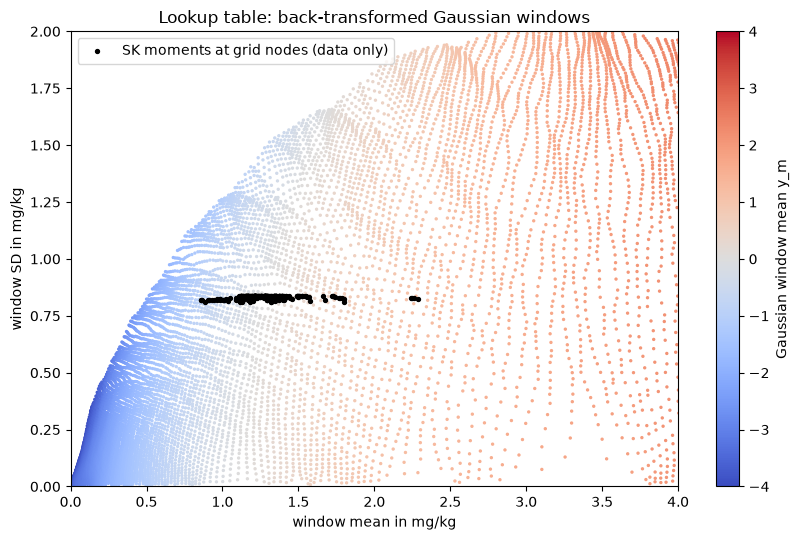

In [11]:
lk = DirectSequentialSimulator(vario_cd, method="lookup", **DSS_KW).fit(grid, df, "Xloc", "Yloc", "Cd")
tab = lk._table
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sc = ax.scatter(tab.mu, tab.sd, c=tab.ym, s=2, cmap="coolwarm")
plt.colorbar(sc, ax=ax, label="Gaussian window mean y_m")
# kriging moments: SK estimate and SD at grid nodes, from the data only (first step of a realization)
from geolattice.geostatistics.simulation.lusim import _cov_block
nb = lk._nbrs[:, :NUM_POINTS]
est, sd = [], []
c00 = vario_cd[4]
for node in np.random.default_rng(1).choice(len(grid), 600, replace=False):
    cand = nb[node][(nb[node] >= 0) & (nb[node] < len(cd))]
    if len(cand) == 0:
        continue
    C = _cov_block(lk._loc[cand], lk._loc[cand], vario_cd, lk._R, same=True)
    c0 = _cov_block(lk._loc[cand], grid[node][None, :], vario_cd, lk._R)[:, 0]
    w = np.linalg.solve(C + 1e-10 * np.eye(len(C)), c0)
    est.append(lk.mean_ + w @ (cd[cand] - lk.mean_)); sd.append(np.sqrt(max(c00 - w @ c0, 0)))
ax.scatter(est, sd, s=8, c="k", label="SK moments at grid nodes (data only)")
ax.set_xlabel("window mean in mg/kg")
ax.set_ylabel("window SD in mg/kg")
ax.set_xlim(0, 4)
ax.set_ylim(0, 2)
ax.set_title("Lookup table: back-transformed Gaussian windows")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The cloud shows the constraint the global histogram imposes: a window with a small mean cannot have a large standard deviation, because cadmium is bounded below by 0. Most kriging moment pairs fall inside the cloud, and the lookup reproduces them exactly. The few outside get the nearest feasible window.

***
## Why Original Units Matter: Block Averages

Remediation, sampling design and mining are decided on **blocks**, not points: the mean cadmium over a field or a management unit. The block mean is a linear average in **mg/kg**, so its variability is governed by the **original-unit covariance**. Under the model, the variance of the means of blocks $v$ within the domain $D$ (the *dispersion variance*) is

$$
D^2(v \mid D) = \bar\gamma(D, D) - \bar\gamma(v, v),
$$

where $\bar\gamma(A, A)$ is the mean variogram between all pairs of points in $A$. A simulator that reproduces the mg/kg variogram reproduces this quantity. One that reproduces a different mg/kg variogram (SGS here, or Soares' biased method) gets block-scale uncertainty wrong, even if its point histogram is right.

Blocks of 10 × 10 nodes (500 m × 500 m) are used; only blocks with at least 90 nodes inside the study area are kept. $\bar\gamma$ is computed from `vario_cd` on the actual node sets.

In [12]:
BLOCK = 10
bx, by = ix // BLOCK, iy // BLOCK
block_id = bx * 1000 + by
ids, counts = np.unique(block_id, return_counts=True)
full = ids[counts >= 90]
members = [np.where(block_id == b)[0] for b in full]
print(f"{len(full)} blocks of 500 m x 500 m with >= 90 nodes")


def gbar(pts_a, pts_b=None):
    # mean model variogram between two point sets (mg/kg)^2
    pts_b = pts_a if pts_b is None else pts_b
    d = np.sqrt(((pts_a[:, None, :] - pts_b[None, :, :]) ** 2).sum(-1))
    g = spherical(d, *vario_cd[1:3], vario_cd[4])
    g[d == 0] = 0.0
    return g.mean()


gbar_v = np.mean([gbar(grid[m]) for m in members[:20]])
dom = grid[np.random.default_rng(3).choice(len(grid), 2000, replace=False)]
gbar_D = gbar(dom)
D2_model = gbar_D - gbar_v
print(f"gamma_bar(v, v) = {gbar_v:.3f}, gamma_bar(D, D) = {gbar_D:.3f}  ->  model dispersion variance D^2(v|D) = {D2_model:.4f}")

# DSS with a larger neighbourhood (48 = the GPU maximum)
real_blocks = dict(real)
real_blocks["DSS lookup, k = 48"] = DirectSequentialSimulator(
    vario_cd, method="lookup", num_points=48, radius=3.0, zmin=ZMIN, zmax=ZMAX, use_gpu=USE_GPU).fit(
    grid, df, "Xloc", "Yloc", "Cd").simulate(N_SIM, seed=2024)
dom_idx = np.random.default_rng(3).choice(len(grid), 1500, replace=False)


def gbar_realized(r, idx):
    # mean semivariance between all pairs of `idx` in realization r
    v = r[idx]
    return 0.5 * np.mean((v[:, None] - v[None, :]) ** 2)


rows = []
block_means = {}
for name, r in real_blocks.items():
    bm = np.stack([r[:, m].mean(1) for m in members], axis=1)          # (nsim, n_blocks)
    block_means[name] = bm
    rows.append({"method": name,
                 "gbar(v,v)": np.mean([gbar_realized(r[i], m) for i in range(10) for m in members[:20]]),
                 "gbar(D,D)": np.mean([gbar_realized(r[i], dom_idx) for i in range(10)]),
                 "D2 of block means": bm.var(1).mean(),
                 "ratio to model": bm.var(1).mean() / D2_model,
                 "blocks with P(mean > 0.8) > 0.9": np.mean((bm > 0.8).mean(0) > 0.9)})
rows.append({"method": "model vario_cd", "gbar(v,v)": gbar_v, "gbar(D,D)": gbar_D, "D2 of block means": D2_model,
             "ratio to model": 1.0})
block_table = pd.DataFrame(rows).set_index("method")
block_table.round(3)

46 blocks of 500 m x 500 m with >= 90 nodes
gamma_bar(v, v) = 0.615, gamma_bar(D, D) = 0.709  ->  model dispersion variance D^2(v|D) = 0.0941


,"gbar(v,v)","gbar(D,D)",D2 of block means,ratio to model,blocks with P(mean > 0.8) > 0.9
method,,,,,
DSS lookup,0.656,0.700,0.050,0.529,0.957
DSS Soares,0.975,1.137,0.105,1.112,1.000
SGS,0.508,0.672,0.097,1.031,0.913
"DSS lookup, k = 48",0.630,0.698,0.080,0.856,0.891
model vario_cd,0.615,0.709,0.094,1.000,NaN


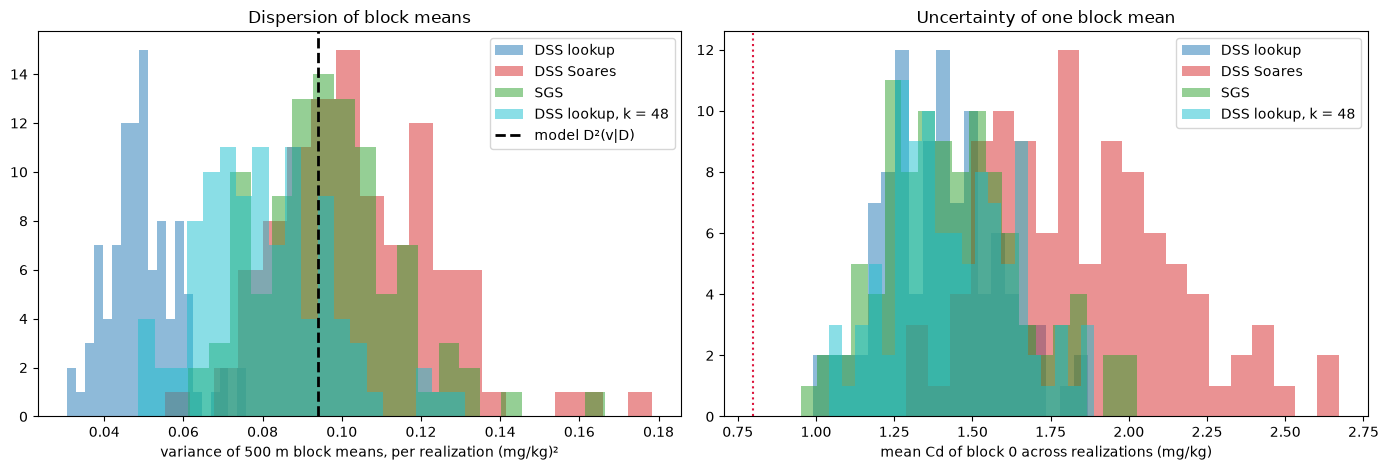

✅ [PASS] DSS lookup (k = 48) reproduces the block dispersion variance within 25%  ratio 0.86 (k = 16: 0.53; SGS 1.03; Soares 1.11)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (name, bm), c in zip(block_means.items(), ["tab:blue", "tab:red", "tab:green", "tab:cyan"]):
    axes[0].hist(bm.var(1), bins=20, alpha=0.5, color=c, label=name)
axes[0].axvline(D2_model, color="k", ls="--", lw=2, label="model D²(v|D)")
axes[0].set_xlabel("variance of 500 m block means, per realization (mg/kg)²")
axes[0].set_title("Dispersion of block means")
axes[0].legend()
k = 0
for (name, bm), c in zip(block_means.items(), ["tab:blue", "tab:red", "tab:green", "tab:cyan"]):
    axes[1].hist(bm[:, k], bins=20, alpha=0.5, color=c, label=name)
axes[1].axvline(0.8, color="crimson", ls=":")
axes[1].set_xlabel(f"mean Cd of block {k} across realizations (mg/kg)")
axes[1].set_title("Uncertainty of one block mean")
axes[1].legend()
plt.tight_layout()
plt.show()
bt = block_table["ratio to model"]
record("DSS lookup (k = 48) reproduces the block dispersion variance within 25%",
       "PASS" if abs(bt["DSS lookup, k = 48"] - 1) < 0.25 else "FAIL",
       f"ratio {bt['DSS lookup, k = 48']:.2f} (k = 16: {bt['DSS lookup']:.2f}; SGS {bt['SGS']:.2f}; Soares {bt['DSS Soares']:.2f})")

The block dispersion variance is a small difference of two large numbers: $\bar\gamma(D,D) - \bar\gamma(v,v) = 0.709 - 0.615 = 0.094$ (mg/kg)². A small error in the short-range variogram therefore changes it a lot.

* **DSS lookup with 16 neighbours** gets only 53% of the model's block variance. Its realizations are slightly too rough *within* the blocks ($\bar\gamma(v,v) = 0.656$ vs 0.615), and that excess alone halves $D^2$. The cause is the sequential neighbourhood approximation. With a nugget of 82% of the sill, only a small structured part of the covariance carries spatial continuity, and 16 neighbours do not transmit it fully along the random path.
* **48 neighbours** (the GPU maximum, with a 3 km radius) bring $\bar\gamma(v,v)$ to 0.630 and the block variance to 86% of the model's. The method was right; the neighbourhood was too small.
* **SGS** matches the model's block variance (103%), but not because it reproduces `vario_cd`: both its within-block and its domain semivariances are lower (0.51 and 0.67). Its own implied variogram happens to give a similar difference. With another variable or block size, that coincidence need not hold.
* **Soares** has the wrong sill altogether ($\bar\gamma(D,D) = 1.14$).

The practical lessons:

* When decisions rest on averages, **check block statistics on the realizations**, and give DSS a large neighbourhood when the variogram is nugget-dominated.
* For a skewed variable the mg/kg variogram is itself uncertain: the few high values dominate its short lags. Its nugget deserves as much scrutiny as the simulator. Robust or rank-based variogram estimators are worth considering.

The rest of the notebook keeps 16 neighbours for comparability with the other notebooks; use `num_points=48` for block-scale work.

***
## Direct Sequential Co-Simulation with Zinc

Zinc is measured at all 359 sites and is correlated with cadmium. It is ordinary-kriged onto the grid (and onto the validation sites) and used as an exhaustive secondary. `fit(..., secondary=zn_grid, secondary_col=...)` standardizes it and estimates $\rho$ as the Pearson correlation between Cd and the secondary at the 259 sites.

Two values of $\rho$ are compared:

* **$\rho$ from measured Zn** (`secondary_col="Zn"`): the correlation with a measurement;
* **$\rho$ from leave-one-out kriged Zn** (`secondary_col="Zn_loo"`): the correlation with the map as it would be at a site without its own Zn sample, which is what the grid nodes actually have.

rho (Cd vs measured Zn)        = 0.609
rho (Cd vs LOO-kriged Zn map)  = 0.396


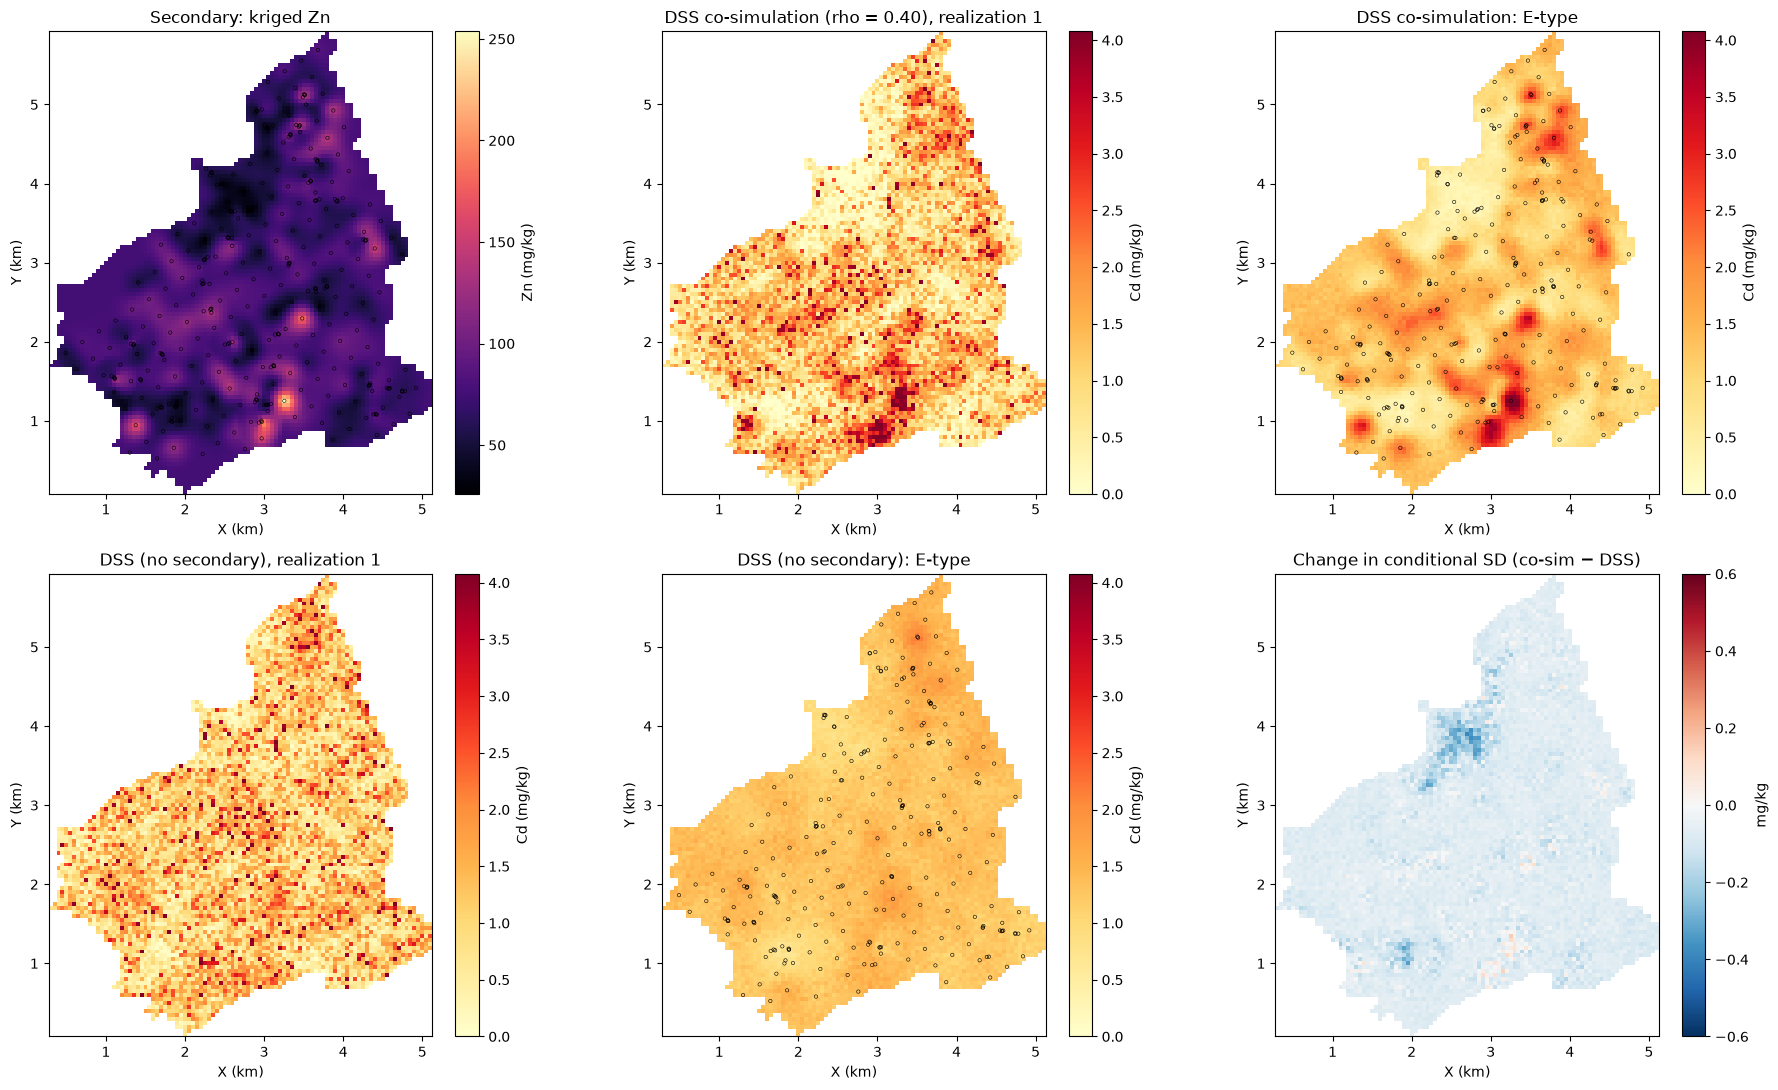

co-simulation: mean 1.310, sd 0.933 (data 1.290, 0.848)


In [14]:
zn_all = df_all["Zn"].to_numpy(float)
vg_zn = Variogram(xy_all, zn_all, model="spherical", n_lags=15).fit()
ok_zn = OrdinaryKriging(vg_zn).fit(xy_all, zn_all)
zn_grid = np.asarray(ok_zn.predict(grid), float)
zn_test = np.asarray(ok_zn.predict(xy_test), float)

pred_rows = np.where(~is_test)[0]
zn_loo = np.empty(len(pred_rows))
for j, i in enumerate(pred_rows):
    keep = np.arange(len(df_all)) != i
    zn_loo[j] = float(np.asarray(OrdinaryKriging(vg_zn).fit(xy_all[keep], zn_all[keep]).predict(xy_all[i:i + 1]))[0])
df["Zn_loo"] = zn_loo

co_meas = DirectSequentialSimulator(vario_cd, use_gpu=USE_GPU, **DSS_KW).fit(
    grid, df, "Xloc", "Yloc", "Cd", secondary=zn_grid, secondary_col="Zn")
co_loo = DirectSequentialSimulator(vario_cd, use_gpu=USE_GPU, **DSS_KW).fit(
    grid, df, "Xloc", "Yloc", "Cd", secondary=zn_grid, secondary_col="Zn_loo")
rho_meas, rho_loo = co_meas.rho_, co_loo.rho_
print(f"rho (Cd vs measured Zn)        = {rho_meas:.3f}")
print(f"rho (Cd vs LOO-kriged Zn map)  = {rho_loo:.3f}")

co_real = co_loo.simulate(N_SIM, seed=2024)
vmax = np.percentile(np.r_[co_real.ravel(), real["DSS lookup"].ravel()], 99)
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
show_map(axes[0, 0], zn_grid, "Secondary: kriged Zn", cmap="magma", label="Zn (mg/kg)", points=xy_all)
show_map(axes[0, 1], co_real[0], f"DSS co-simulation (rho = {rho_loo:.2f}), realization 1", vmin=0, vmax=vmax)
show_map(axes[0, 2], co_real.mean(0), "DSS co-simulation: E-type", vmin=0, vmax=vmax, points=xy)
show_map(axes[1, 0], real["DSS lookup"][0], "DSS (no secondary), realization 1", vmin=0, vmax=vmax)
show_map(axes[1, 1], real["DSS lookup"].mean(0), "DSS (no secondary): E-type", vmin=0, vmax=vmax, points=xy)
show_map(axes[1, 2], co_real.std(0) - real["DSS lookup"].std(0), "Change in conditional SD (co-sim − DSS)",
         cmap="RdBu_r", vmin=-0.6, vmax=0.6, label="mg/kg")
plt.tight_layout()
plt.show()
print(f"co-simulation: mean {co_real.mean():.3f}, sd {co_real.std(1).mean():.3f} (data {cd.mean():.3f}, {cd.std():.3f})")

***
## Validation at 100 Held-Out Sites

All variants draw 300 realizations on the grid plus the 100 validation sites (with kriged Zn there for co-simulation), and are scored on the true cadmium:

| Metric | Meaning | Better |
|---|---|---|
| RMSE of the E-type | accuracy of the mean of the realizations | lower |
| coverage / width of the 80% interval | calibration and sharpness of the local distributions | coverage ≈ 0.80, then narrower |
| Brier score of $P(\text{Cd} > 0.8)$ | quality of the exceedance probability | lower |
| CRPS | quality of the whole local distribution | lower |

In [15]:
N_VAL = 300
val_grid = np.vstack([grid, xy_test])
zn_val = np.r_[zn_grid, zn_test]
VAL = slice(len(grid), None)


def crps_ensemble(ens, obs):
    ens = np.sort(ens, axis=0)
    m = ens.shape[0]
    w = (2 * np.arange(1, m + 1) - m - 1) / (m * m)
    return np.abs(ens - obs).mean(0) - (w[:, None] * ens).sum(0)


def score(name, ens):
    et = ens.mean(0)
    lo, hi = np.percentile(ens, [10, 90], axis=0)
    p = (ens > 0.8).mean(0)
    return {"method": name, "RMSE": np.sqrt(np.mean((et - truth) ** 2)),
            "cover80": np.mean((truth >= lo) & (truth <= hi)), "width80": np.mean(hi - lo),
            "Brier(0.8)": np.mean((p - (truth > 0.8)) ** 2), "CRPS": crps_ensemble(ens, truth).mean()}


def dss_val(method="lookup", **fit_kw):
    sim = DirectSequentialSimulator(vario_cd, method=method, use_gpu=USE_GPU,
                                    rho=fit_kw.pop("rho", None), **DSS_KW)
    return sim.fit(val_grid, df, "Xloc", "Yloc", "Cd", **fit_kw).simulate(N_VAL, seed=1)[:, VAL]


ens = {
    "SGS": sgsim_gpu(val_grid, df, "Xloc", "Yloc", "Cd", vario_ns, num_points=NUM_POINTS, radius=RADIUS,
                     nsim=N_VAL, seed=1, zmin=ZMIN, zmax=ZMAX, use_gpu=USE_GPU)[:, VAL],
    "DSS lookup": dss_val("lookup"),
    "DSS Soares": dss_val("soares"),
    f"DSS co-sim, rho_meas = {rho_meas:.2f}": dss_val(secondary=zn_val, rho=rho_meas),
    f"DSS co-sim, rho_loo = {rho_loo:.2f}": dss_val(secondary=zn_val, rho=rho_loo),
}
val_table = pd.DataFrame([score(k, v) for k, v in ens.items()]).set_index("method")
val_table.round(3)

,RMSE,cover80,width80,Brier(0.8),CRPS
method,,,,,
SGS,0.744,0.87,1.785,0.160,0.370
DSS lookup,0.779,0.88,1.882,0.180,0.398
DSS Soares,0.890,0.72,2.611,0.222,0.466
"DSS co-sim, rho_meas = 0.61",0.831,0.67,1.362,0.147,0.455
"DSS co-sim, rho_loo = 0.40",0.701,0.82,1.623,0.139,0.378


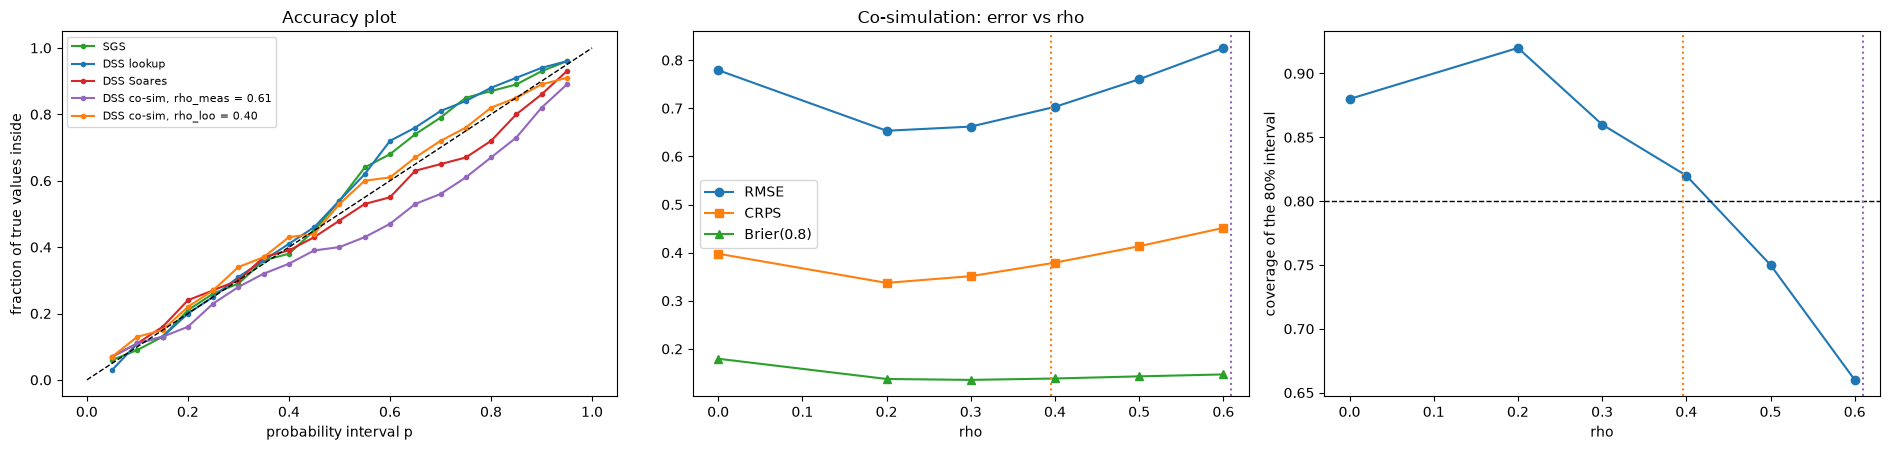

✅ [PASS] DSS co-sim (rho_loo) beats DSS without secondary on CRPS  0.398 -> 0.378
✅ [PASS] DSS co-sim (rho_loo) 80% coverage in [0.70, 0.90]  coverage 0.82


,RMSE,cover80,width80,Brier(0.8),CRPS
rho,,,,,
0.0,0.779,0.88,1.882,0.180,0.398
0.2,0.653,0.92,1.812,0.138,0.337
0.3,0.662,0.86,1.730,0.136,0.351
0.4,0.703,0.82,1.619,0.139,0.379
0.5,0.760,0.75,1.504,0.143,0.413
0.6,0.825,0.66,1.376,0.147,0.451


In [16]:
scan = []
for rho in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]:
    e = dss_val(secondary=zn_val, rho=rho)
    scan.append({**score(f"rho = {rho}", e), "rho": rho})
scan = pd.DataFrame(scan).set_index("rho").drop(columns="method")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
ps = np.linspace(0.05, 0.95, 19)
for (name, e), c in zip(ens.items(), ["tab:green", "tab:blue", "tab:red", "tab:purple", "tab:orange"]):
    frac = [np.mean((truth >= np.percentile(e, 50 - 50 * p, axis=0)) & (truth <= np.percentile(e, 50 + 50 * p, axis=0)))
            for p in ps]
    axes[0].plot(ps, frac, "o-", ms=3, c=c, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("probability interval p")
axes[0].set_ylabel("fraction of true values inside")
axes[0].set_title("Accuracy plot")
axes[0].legend(fontsize=8)
axes[1].plot(scan.index, scan["RMSE"], "o-", label="RMSE")
axes[1].plot(scan.index, scan["CRPS"], "s-", label="CRPS")
axes[1].plot(scan.index, scan["Brier(0.8)"], "^-", label="Brier(0.8)")
axes[1].set_xlabel("rho")
axes[1].set_title("Co-simulation: error vs rho")
axes[1].legend()
axes[2].plot(scan.index, scan["cover80"], "o-")
axes[2].axhline(0.8, color="k", ls="--", lw=1)
axes[2].set_xlabel("rho")
axes[2].set_ylabel("coverage of the 80% interval")
for ax in axes[1:]:
    ax.axvline(rho_loo, color="tab:orange", ls=":")
    ax.axvline(rho_meas, color="tab:purple", ls=":")
plt.tight_layout()
plt.show()

v = val_table
row_loo = v.loc[f"DSS co-sim, rho_loo = {rho_loo:.2f}"]
record("DSS co-sim (rho_loo) beats DSS without secondary on CRPS", "PASS" if row_loo.CRPS < v.loc["DSS lookup", "CRPS"]
       else "FAIL", f"{v.loc['DSS lookup', 'CRPS']:.3f} -> {row_loo.CRPS:.3f}")
record("DSS co-sim (rho_loo) 80% coverage in [0.70, 0.90]", "PASS" if 0.70 <= row_loo.cover80 <= 0.90 else "FAIL",
       f"coverage {row_loo.cover80:.2f}")
scan.round(3)

* **At the point scale, DSS without a secondary is slightly worse than SGS** (RMSE 0.78 vs 0.74 mg/kg, CRPS 0.40 vs 0.37, Brier 0.180 vs 0.160), with similar coverage. DSS's advantage is the original-unit covariance (Section 9), not local accuracy. Kriging the raw, nugget-dominated values gives less weight to the neighbours than kriging the better-structured normal scores.
* **Soares' method** is the worst on every measure: its local distributions are shifted upward, so they are wide and still miss (coverage 0.72).
* **Co-simulation with $\rho$ from measured Zn** (0.61) is over-confident: narrow intervals and coverage 0.67, the same failure seen in [`sgcosim`](05_07_02_sgcosim.ipynb).
* **Co-simulation with $\rho$ from the leave-one-out kriged map** (0.40) is calibrated (coverage 0.82). It improves on DSS without a secondary (RMSE 0.78 → 0.70, CRPS 0.40 → 0.38, Brier 0.180 → 0.139) and beats SGS on RMSE and Brier.
* **The $\rho$ scan** puts the best values a little lower, around 0.2-0.3 (RMSE 0.65, CRPS 0.34). That scan uses the validation data, so it is optimistic. The leave-one-out estimate needs no held-out data and lands close to it, while the measurement-based $\rho$ is far too high.

***
## Visualization of Spatial Uncertainty

The co-simulated realizations (lookup, $\rho$ from the LOO-kriged map) are used to map uncertainty.

### Animated display of realizations

The first 20 realizations in sequence, on one colour scale.

In [17]:
N_FRAMES = 20
plt.rcParams["animation.embed_limit"] = 50
fig_anim, ax_anim = plt.subplots(figsize=(7.2, 7.6))
im_anim = ax_anim.imshow(to_image(co_real[0]), origin="lower", extent=EXTENT, cmap="YlOrRd", vmin=0, vmax=vmax)
ax_anim.scatter(xy[:, 0], xy[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
plt.colorbar(im_anim, ax=ax_anim, label="Cd (mg/kg)", fraction=0.046, pad=0.04)
ax_anim.set_xlabel("X (km)")
ax_anim.set_ylabel("Y (km)")
title_anim = ax_anim.set_title(f"DSS co-simulated Cd, realization 1 / {N_FRAMES}")


def _update(frame):
    im_anim.set_data(to_image(co_real[frame]))
    title_anim.set_text(f"DSS co-simulated Cd, realization {frame + 1} / {N_FRAMES}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_FRAMES, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Conditional quantile maps (q10, median, q90)

A high q10 marks areas where cadmium is *certainly high*; a low q90 marks areas where it is *certainly low* (Goovaerts, 1997).

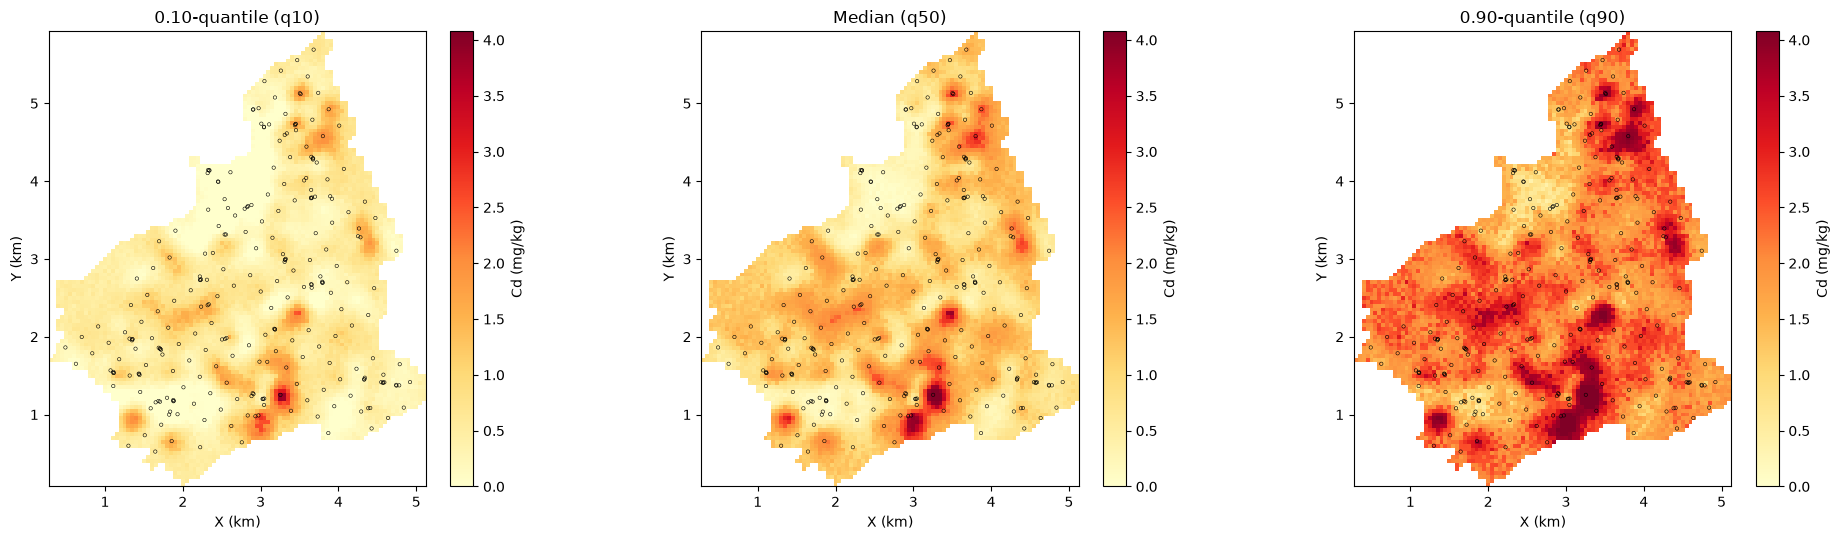

In [18]:
q10, q50, q90 = np.quantile(co_real, [0.10, 0.50, 0.90], axis=0)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, vals, title in zip(axes, (q10, q50, q90), ("0.10-quantile (q10)", "Median (q50)", "0.90-quantile (q90)")):
    show_map(ax, vals, title, vmin=0, vmax=vmax, points=xy)
plt.tight_layout()
plt.show()

### Probability of exceeding the guide value

The fraction of realizations above 0.8 mg/kg, at each node and for each 500 m block mean.

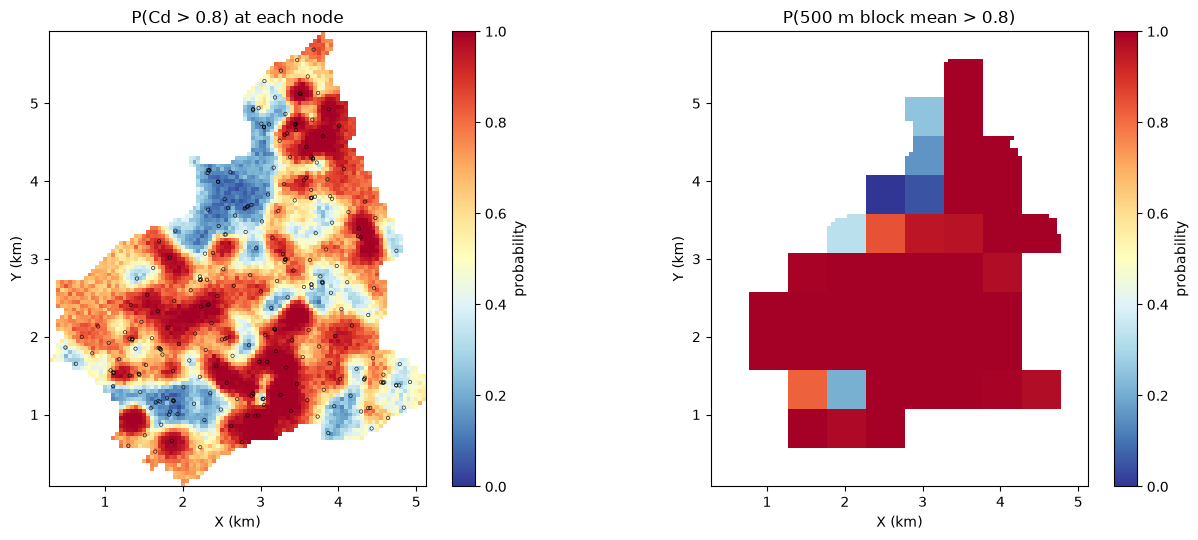

nodes with P < 0.1 or P > 0.9: 20%;  blocks with P < 0.1 or P > 0.9: 87%


In [19]:
p_node = (co_real > 0.8).mean(0)
co_bm = np.stack([co_real[:, m].mean(1) for m in members], axis=1)
p_block = np.full(len(grid), np.nan)
for m, p in zip(members, (co_bm > 0.8).mean(0)):
    p_block[m] = p
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
show_map(axes[0], p_node, "P(Cd > 0.8) at each node", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability", points=xy)
show_map(axes[1], p_block, "P(500 m block mean > 0.8)", cmap="RdYlBu_r", vmin=0, vmax=1, label="probability")
plt.tight_layout()
plt.show()
print(f"nodes with P < 0.1 or P > 0.9: {np.mean((p_node < .1) | (p_node > .9)):.0%};  "
      f"blocks with P < 0.1 or P > 0.9: {np.mean(((co_bm > .8).mean(0) < .1) | ((co_bm > .8).mean(0) > .9)):.0%}")

Block means are far more certain than single points: averaging over 100 nodes cancels most of the short-range (nugget-dominated) variability. Most blocks are confidently above or below the guide value, while single nodes rarely are. How much more certain depends on the original-unit covariance. Section 9 showed that with 16 neighbours DSS understates block variability, so these block probabilities are somewhat over-confident; for block decisions, use `num_points=48`.

***
## CPU vs GPU Timing

DSS with the lookup method (no secondary) on the full 5,957-node grid, timed for several `nsim` after a one-realization GPU warm-up. The CPU and GPU realizations are compared at every `nsim`.

 nsim CPU (s) GPU (s) speedup max |GPU-CPU|
    1    0.44    1.93    0.2x       2.8e-14
    8    3.47    1.98    1.8x       2.8e-14
   32   13.80    1.98    7.0x       2.8e-14
  128   55.16    2.29   24.1x       5.1e-14


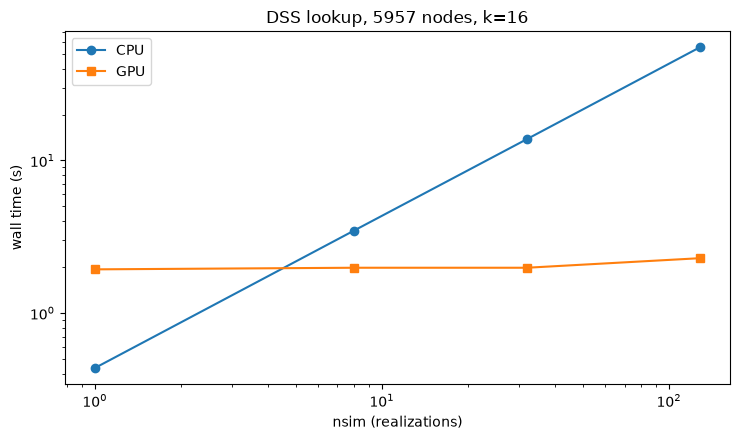

✅ [PASS] GPU DSS equals CPU (all nsim)  max diff 5.1e-14; speedup at nsim=128: 24.1x


In [20]:
NSIM_LIST = [1, 8, 32, 128]
cpu_sim = DirectSequentialSimulator(vario_cd, use_gpu=False, **DSS_KW).fit(grid, df, "Xloc", "Yloc", "Cd")
gpu_sim = DirectSequentialSimulator(vario_cd, use_gpu=True, **DSS_KW).fit(grid, df, "Xloc", "Yloc", "Cd") if USE_GPU else None
if USE_GPU:
    gpu_sim.simulate(1, seed=0)
    cp.cuda.Device(0).synchronize()
rows = []
for nsim in NSIM_LIST:
    t0 = time.perf_counter()
    out_cpu = cpu_sim.simulate(nsim, seed=5)
    row = {"nsim": nsim, "CPU (s)": time.perf_counter() - t0, "GPU (s)": np.nan, "speedup": np.nan, "max |GPU-CPU|": np.nan}
    if USE_GPU:
        t0 = time.perf_counter()
        out_gpu = gpu_sim.simulate(nsim, seed=5)
        cp.cuda.Device(0).synchronize()
        row["GPU (s)"] = time.perf_counter() - t0
        row["speedup"] = row["CPU (s)"] / row["GPU (s)"]
        row["max |GPU-CPU|"] = float(np.abs(out_gpu - out_cpu).max())
    rows.append(row)
bench = pd.DataFrame(rows)
print(bench.to_string(index=False, formatters={"CPU (s)": "{:.2f}".format, "GPU (s)": "{:.2f}".format,
                                               "speedup": "{:.1f}x".format, "max |GPU-CPU|": "{:.1e}".format}))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(bench["nsim"], bench["CPU (s)"], "o-", label="CPU")
if USE_GPU:
    ax.loglog(bench["nsim"], bench["GPU (s)"], "s-", label="GPU")
ax.set_xlabel("nsim (realizations)")
ax.set_ylabel("wall time (s)")
ax.set_title(f"DSS lookup, {len(grid)} nodes, k={NUM_POINTS}")
ax.legend()
plt.tight_layout()
plt.show()
if USE_GPU:
    record("GPU DSS equals CPU (all nsim)", "PASS" if bench["max |GPU-CPU|"].max() < 1e-6 else "FAIL",
           f"max diff {bench['max |GPU-CPU|'].max():.1e}; speedup at nsim={NSIM_LIST[-1]}: {bench['speedup'].iloc[-1]:.1f}x")

On this run (RTX A5500 Laptop GPU; numbers will vary):

* The CPU engine needs about 0.43 s per realization (54 s for 128).
* The GPU time is almost flat at about 2 s from 1 to 128 realizations: one thread block per realization leaves the GPU mostly idle until `nsim` is large. The GPU is about 5× slower for one realization, breaks even at a few realizations, and is 23× faster at 128.
* CPU and GPU realizations agree to about $10^{-13}$ mg/kg.

***
## Summary and Conclusions

In [21]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,GlobalDistribution: from_gaussian(to_gaussian(...,PASS,max error 1.8e-15
1,DSS: exact conditioning,PASS,max |sim - data| = 0.0e+00
2,DSS: realizations vary away from data,PASS,mean std across realizations = 0.67 mg/kg
3,DSS: same seed -> identical,PASS,
4,DSS: different seed -> different,PASS,
5,DSS (lookup): GPU = CPU for the same seed,PASS,max diff = 2.8e-14 mg/kg
6,DSS (soares): GPU = CPU for the same seed,PASS,max diff = 2.8e-14 mg/kg
7,dssim_direct == DirectSequentialSimulator(...)...,PASS,max diff = 2.8e-14
8,soares warns for skewed data,PASS,
9,DSS lookup reproduces the mean within 5%,PASS,1.303 vs data 1.290


- **Direct sequential simulation** kriges cadmium in mg/kg with the mg/kg variogram and draws each value from a local distribution with the kriging mean and variance, built from the global histogram. Conditioning is exact, CPU and GPU agree to about $10^{-13}$, and no back-transform is needed.
- **The lookup method** (Oz et al., 2003) reproduced the Cd histogram (mean 1.30 vs 1.29 mg/kg, standard deviation 0.84 vs 0.85) and the mg/kg variogram at the binned lags. **Soares' method** drifted by +35% in the mean on this skewed variable, as theory predicts. GeoLattice warns about it.
- **Block averages** are where original units matter, and they are sensitive. With a nugget of 82% of the sill and 16 neighbours, DSS realizations were slightly too rough at short range and gave only 53% of the model's block dispersion variance; 48 neighbours raised that to 86%. SGS matched the block variance through its own implied variogram, not the modelled one. Check block statistics, and use a large neighbourhood for block-scale DSS.
- **At the point scale**, DSS without a secondary was slightly less accurate than SGS on held-out sites. **Co-simulation with zinc**, with $\rho$ from the leave-one-out kriged map (0.40), was calibrated and the best of the variants compared (RMSE 0.70 mg/kg, Brier 0.139). With $\rho$ from Zn measurements it was over-confident.
- **GPU:** `use_gpu=True` gives identical realizations, about 23× faster at 128 realizations on this grid.

| Object | Role in this notebook |
|---|---|
| `DirectSequentialSimulator` | DSS in mg/kg (`method="lookup"` / `"soares"`), co-simulation with the Zn map, CPU or GPU |
| `dssim_direct` | One-call DSS |
| `GlobalDistribution` | Global cdf of Cd with linear tails to `zmin` / `zmax`; `to_gaussian` / `from_gaussian` |
| `sgsim_gpu` | SGS baseline (normal scores, back-transformed) |
| `Variogram` / `OrdinaryKriging` | Kriged Zn map and its leave-one-out values |

### Choosing the options

| Situation | Choice |
|---|---|
| Decisions on block or field averages, flow or volume calculations in original units | DSS, `method="lookup"`: the mg/kg variogram is reproduced |
| Point-scale probabilities or local prediction only | SGS is as good or better, and its normal-score variogram is easier to model |
| Skewed variable (skewness > 1) | never `method="soares"`: its mean and variance drift upward |
| Near-symmetric variable | either method; Soares is slightly faster |
| Exhaustive secondary | `fit(secondary=..., secondary_col=...)`; estimate $\rho$ against the map as used at the nodes (LOO), and validate |
| Clustered samples | pass declustering `weights` (histogram and mean) |
| Many realizations, GPU available | `use_gpu=True`: identical realizations, faster at large `nsim` |

***
## References

| Reference | Used for |
|---|---|
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |
| Journel, A.G. (1994). Modeling uncertainty: some conceptual thoughts. In Dimitrakopoulos, R. (ed.), *Geostatistics for the Next Century*, 30-43. Kluwer. | The DSS principle: any local distribution with the SK mean and variance reproduces the covariance |
| Soares, A. (2001). Direct sequential simulation and cosimulation. *Mathematical Geology* 33, 911-926. | Soares' method and direct sequential co-simulation |
| Oz, B., Deutsch, C.V., Tran, T.T. & Xie, Y. (2003). DSSIM-HR: A FORTRAN 90 program for direct sequential simulation with histogram reproduction. *Computers & Geosciences* 29, 39-51. | The lookup-table method |
| Rivoirard, J. (1994). *Introduction to Disjunctive Kriging and Non-Linear Geostatistics*. Oxford University Press. | Hermitian expansion of the original-unit covariance |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura case study, quantile and probability maps |
| Journel, A.G. & Huijbregts, C.J. (1978). *Mining Geostatistics*. Academic Press. | Dispersion variance of block averages |
| Deutsch, C.V. & Journel, A.G. (1998). *GSLIB: Geostatistical Software Library and User's Guide*, 2nd ed. Oxford University Press. | Variogram conventions, `sgsim` |
| Gneiting, T. & Raftery, A.E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association* 102, 359-378. | CRPS |